# Лабораторная работа 5. Градиентный бустинг

Цель эксперимента — сравнить sklearn и собственную реализацию на классификации переписчиков и оценке мощности волновой фермы. Все варианты оцениваются на одних и тех же объектах.

## Задачи и разбиение


**Avila** содержит десять признаков геометрии текстовых фрагментов латинской рукописи XII века. Классификация по переписчикам позволяет предварительно распределять фрагменты перед проверкой палеографом. Используется разбиение UCI. Номера страниц в признаках отсутствуют, поэтому результаты относятся к этому протоколу и одному манускрипту. [Источник и словарь признаков](https://doi.org/10.24432/C5K02X)

**Wave Energy Converters · Tasmania.** По координатам 16 преобразователей требуется оценить суммарную мощность фермы. Такой прогноз может ускорить отбор вариантов перед запуском гидродинамического симулятора. 16 индивидуальных мощностей исключены: их сумма практически равна целевой переменной. Разбиение учитывает группы конфигураций по координатам, округлённым до 10 м. Соседние конфигурации по разные стороны границы округления могут оказаться в разных частях. Данные охватывают один волновой сценарий. [Источник и схема данных](https://doi.org/10.24432/C5831S)

Обе задачи используют по три внутренних фолда. В каждом фолде масштабирование и модель подгоняются только по его обучающей части. Holdout одинаков для всех пяти работ и используется после выбора конфигураций.

In [1]:
# Загружаем фиксированные разбиения и общие функции эксперимента.
import pandas as pd
from IPython.display import Markdown, display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 5
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila — автор фрагмента,20867,10430,10437,10,Официальные train/test; 3 стратифицированных ф...
1,Tasmania — суммарная мощность (МВт),72000,5762,1438,32,Групповой holdout 20% групп; 3 групповых фолда...


,Avila — автор фрагмента
Точных совпадений векторов признаков между train/test,0


,Tasmania — суммарная мощность (МВт)
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Выбор метрик


**Avila.** Macro-F1 усредняет F1 по всем 12 классам, сохраняя вклад редких переписчиков. Balanced accuracy — средняя полнота по классам. Accuracy показывает долю верных ответов по всем фрагментам.

**Tasmania.** MAE в МВт показывает средний абсолютный промах. RMSE в тех же единицах сильнее учитывает большие ошибки. R² отражает долю объяснённой вариации относительно среднего отклика теста и может быть отрицательным.

Для проверки полезности моделей используется простой ориентир. Классификационный dummy всегда выбирает самый частый класс train, регрессионный — медиану train. Основные метрики для выбора конфигурации — macro-F1 (выше) и MAE (ниже).

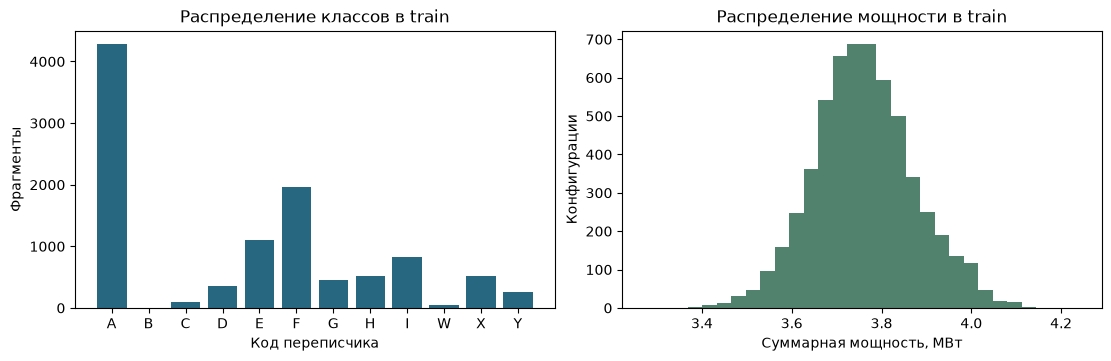

In [2]:
# Изучаем дисбаланс классов и масштаб мощности на обучающих данных.
plot_training(tasks)

## Библиотечный бейзлайн

Библиотечный бейзлайн использует 32 итерации, глубину 2, минимум 5 объектов в листе и шаг 0,1. Для классификации оптимизируется мультиномиальная log-loss, для регрессии — квадратичная ошибка.

## Гипотезы и кросс-валидация

Проверяем, дают ли более глубокие слабые деревья и большее число итераций прирост на валидации. В классификации также проверяем меньший шаг с большим числом итераций. В регрессии сравниваем геометрию отдельно и вместе с исходными координатами.

В сетку включён бейзлайн. При равенстве средних метрик приоритет получает первая конфигурация. В таблицах приведены оценки каждого фолда и стандартное отклонение между фолдами.

In [3]:
# Проверяем гипотезы на трёх внутренних фолдах и фиксируем победителей.
selections = select_candidates(LAB, tasks)
for task in tasks:
    display(Markdown(f"**{task.title} · {primary_metric(task)}**"))
    display(selections[task.key][2].round(5))

**Avila — автор фрагмента · macro_f1**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.72007,0.02000,0.70127,0.71785,0.74109,False
1,Глубина 3 и 48 итераций,raw,"{""max_depth"": 3, ""n_estimators"": 48}",0.88832,0.02913,0.88295,0.86225,0.91976,False
2,Глубина 4,raw,"{""max_depth"": 4}",0.91058,0.03155,0.92028,0.87533,0.93614,True
3,Меньший шаг и 64 итерации,raw,"{""learning_rate"": 0.05, ""n_estimators"": 64}",0.75493,0.03285,0.76876,0.71743,0.77860,False


**Tasmania — суммарная мощность (МВт) · mae_mw**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.07368,0.00087,0.07468,0.07316,0.07319,False
1,Геометрия,geometry,{},0.05900,0.00093,0.05847,0.06008,0.05846,False
2,Глубина 3 и 48 итераций,raw,"{""max_depth"": 3, ""n_estimators"": 48}",0.06312,0.00042,0.06360,0.06289,0.06287,False
3,Геометрия и глубина 3,geometry,"{""max_depth"": 3, ""n_estimators"": 48}",0.05314,0.00076,0.05296,0.05397,0.05249,False
4,"Координаты и геометрия, глубина 3",combined,"{""max_depth"": 3, ""n_estimators"": 48}",0.05168,0.00074,0.05100,0.05247,0.05156,True


## Оценка sklearn на отложенной выборке

Переобучаем бейзлайн и победителя CV на всём train. В итоговом сравнении сохраняем фактический результат даже при снижении качества на holdout.

In [4]:
# Получаем holdout-метрики и сохраняем прогнозы для анализа ошибок.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    display(Markdown(f"**{task.title}**"))
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,5.46768,0.03837,0.78335,0.73829,0.75328
2,sklearn tuned,Глубина 4,11.23165,0.04942,0.92901,0.91141,0.88867


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.99293,0.00089,0.07457,0.09615,0.26670
2,sklearn tuned,"Координаты и геометрия, глубина 3",3.52265,0.02703,0.05014,0.06676,0.64647


## Собственная реализация

Регрессионный бустинг начинает со среднего, строит дерево на остатках y − f(x) и добавляет его прогноз с коэффициентом shrinkage. Классификационный бустинг начинает с логарифмов априорных частот и на каждой итерации строит дерево для каждого класса на градиенте yₖ − pₖ. В листе амплитуда вычисляется по отношению суммы остатков к сумме pₖ(1 − pₖ) с множителем (K − 1)/K. Вероятности для всех деревьев итерации считаются до её обновления.

Параметры и преобразования переносятся из библиотечного бейзлайна и лучшей библиотечной конфигурации соответственно. Повторного подбора по holdout нет. [Код оценивателей](labkit/models.py)

In [5]:
# Сопоставляем две собственные версии с эквивалентными конфигурациями sklearn.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    display(Markdown(f"**{task.title}**"))
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,5.46768,0.03837,0.78335,0.73829,0.75328
2,sklearn tuned,Глубина 4,11.23165,0.04942,0.92901,0.91141,0.88867
3,own baseline,Бейзлайн,8.40421,0.04030,0.78335,0.73829,0.75328
4,own tuned,Глубина 4,15.64946,0.10385,0.93160,0.91448,0.89183


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.99293,0.00089,0.07457,0.09615,0.26670
2,sklearn tuned,"Координаты и геометрия, глубина 3",3.52265,0.02703,0.05014,0.06676,0.64647
3,own baseline,Бейзлайн,1.16847,0.00074,0.07457,0.09615,0.26670
4,own tuned,"Координаты и геометрия, глубина 3",4.99707,0.03281,0.05014,0.06676,0.64647


## Диагностика ошибок

Матрица ошибок нормирована по истинному классу. Точки на графике мощности сравниваются с диагональю идеального прогноза. Обе визуализации относятся к варианту sklearn, выбранному по CV.

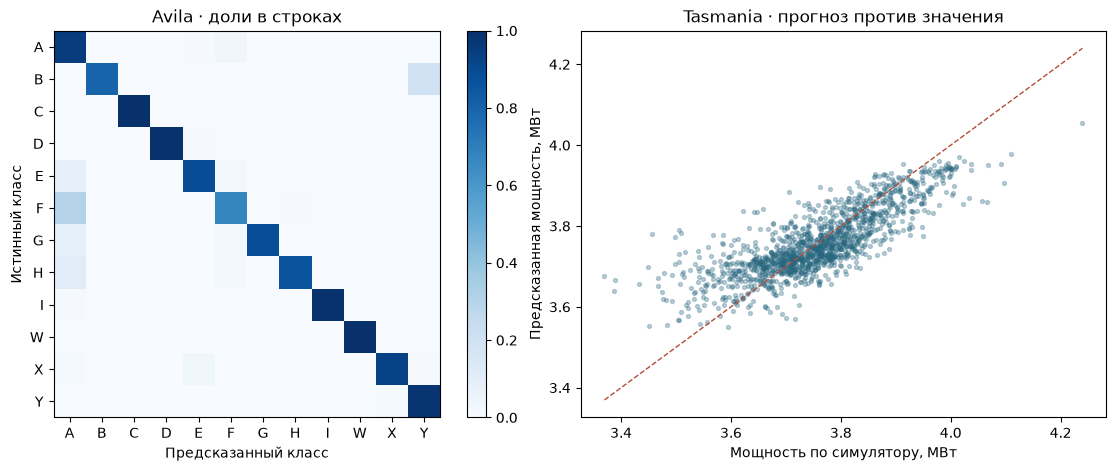

In [6]:
# Визуализируем ошибки классификации и отклонения мощности на holdout.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Формируем вывод из измеренных метрик и экспортируем входные данные для сводки.
display(Markdown(comparison_text(tasks, results, selections)))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

**Avila — автор фрагмента.** По CV выбран вариант «Глубина 4» (macro-F1 0.9106, бейзлайн 0.7201). На holdout macro-F1 sklearn улучшился относительно бейзлайна: 0.7833 → 0.9290. Собственная реализация: 0.7833 → 0.9316. Разница собственной модели и sklearn macro-F1: +0.0000 в бейзлайне, +0.0026 после настройки.

**Tasmania — суммарная мощность (МВт).** По CV выбран вариант «Координаты и геометрия, глубина 3» (MAE 0.0517 МВт, бейзлайн 0.0737 МВт). На holdout MAE sklearn улучшился относительно бейзлайна: 0.0746 → 0.0501 МВт. Собственная реализация: 0.0746 → 0.0501 МВт. Разница собственной модели и sklearn MAE: +0.0000 МВт в бейзлайне, +0.0000 МВт после настройки.

Метрики сохранены в results/lab_05.csv
